# AI 트렌드

## AI 에이전트

AI 에이전트는 사용자가 정한 목표를 이루기 위해 AI 모델을 써서 직접 움직이는 시스템입니다. 생각하고 계획하고 툴을 써서 실행하는 걸 한 번에 합니다.

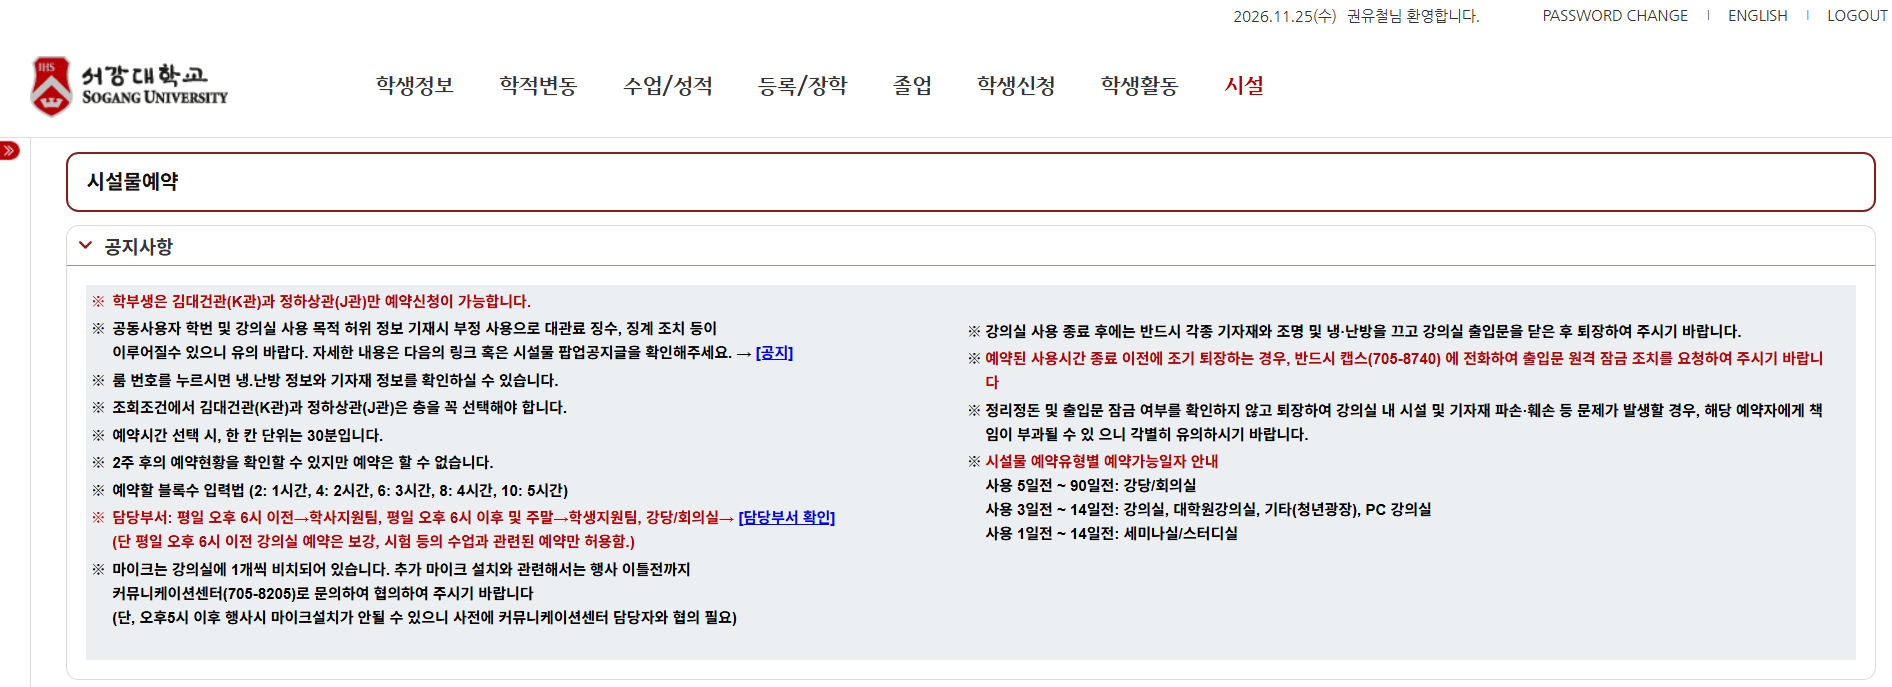

생성형 AI는 질문하면 답을 한 번 내놓고 끝나지만, 에이전틱 AI는 목표를 이룰 때까지 생각하고 행동하는 걸 반복합니다. 예를 들어 "세션 강의 장소 잡아줘"라고 하면 생성형 AI는 예약하는 방법을 알려주고 끝나지만, 에이전트는 직접 서강대 SAINT에 들어가서 빈 강의실을 찾고 예약까지 합니다.

### ReAct

에이전트가 움직이는 방식을 ReAct라고 하는데 생각, 행동, 관찰을 계속 반복합니다.

예를 들어 화요일 저녁 빈 강의실부터 찾아야겠다고 생각하고, SAINT에서 강의실을 조회하고, K202가 비어 있는걸 보고, 30명이 들어가는지 확인해야겠다고 다시 생각하는 식입니다.

관찰한 결과에 따라 다음 생각이 바뀌는게 핵심입니다. 그리고 에이전트가 계속 돌기만 하면 안되니까 최대 반복 횟수, 비용 한도, 중요한 행동 전 사람 승인 같은 제한을 앱에서 정해 둡니다.

### 다중 에이전트

여러 에이전트가 역할을 나눠서 같이 일하는 구조입니다. 오케스트레이터가 일을 쪼개서 나눠주고 결과를 합치고, 서브 에이전트는 맡은 일만 합니다. 학회 행사로 치면 회장이 대외협력팀, 교육팀, 운영지원팀한테 일을 나눠주는 것과 비슷합니다.

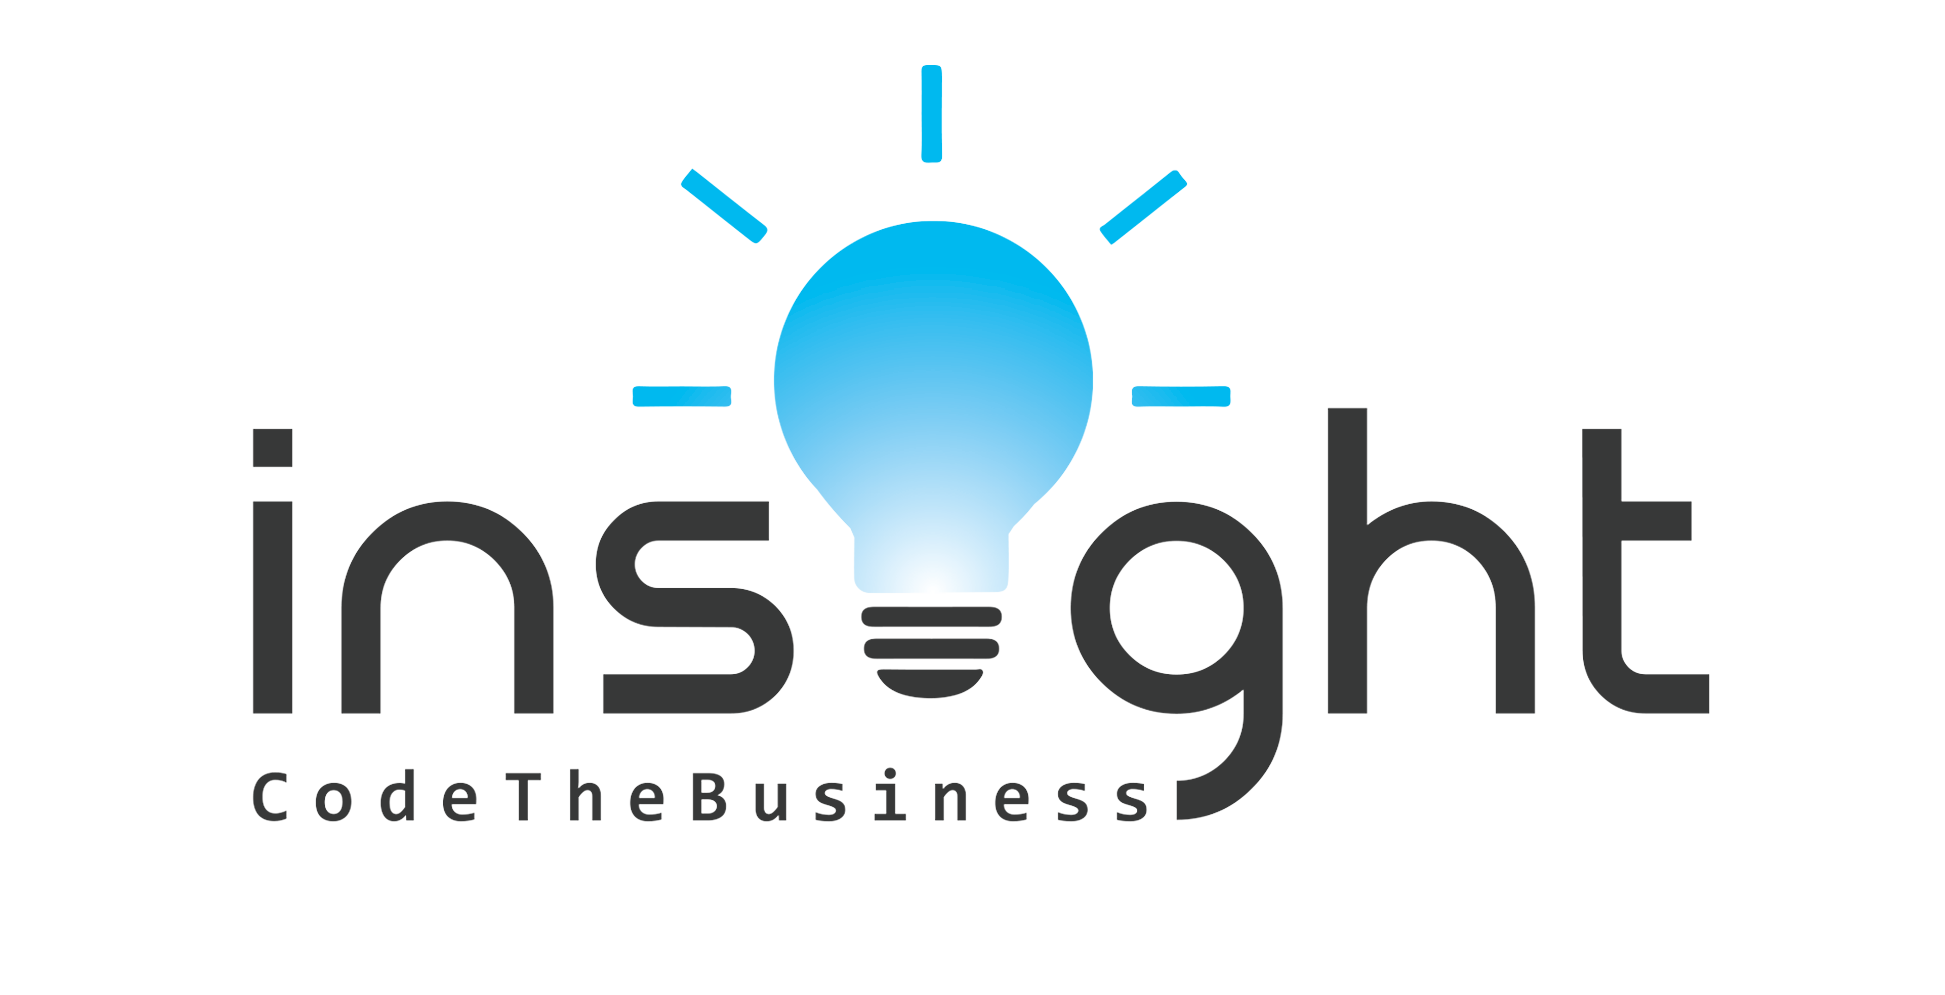

혼자 다 하면 처음 판단을 그대로 믿고 넘어가기 쉬운데, 검토를 다른 에이전트가 하면 실수를 더 잘 잡을 수 있습니다. 대신 돈이 좀 많이 들어서 좋은 모델도 쓰지만 가벼운 모델도 섞어 쓰는게 좋습니다.

그렇다고 무조건 다중 에이전트가 좋은건 아니고, 순서가 정해진 단순한 일은 정해진 순서대로 돌리고, 툴 몇 개로 끝나는 일은 에이전트 하나로, 따로 조사해서 합칠 수 있는 큰 일만 다중 에이전트로 하는게 좋습니다.

## MCP

### Function Calling

모델이 툴을 직접 실행하는건 아니고, "이 함수를 이 값으로 불러줘"라고 요청만 내놓는 기능입니다.

앱이 모델한테 질문이랑 쓸 수 있는 함수 목록을 주면, 모델이 어떤 함수를 어떤 값으로 부를지 적어서 내놓고, 앱이 그걸 실제로 실행해서 결과를 다시 주면 모델이 최종 답을 씁니다.

### MCP가 필요한 이유

표준이 없으면 앱마다, 툴마다 연결 코드를 따로 짜야 해서 앱이 n개 툴이 m개면 n×m개를 만들어야 합니다. 그런데 MCP라는 공통 규격을 쓰면 앱은 MCP 클라이언트를 한 번, 툴은 MCP 서버를 한 번만 만들면 돼서 n+m개로 줄어듭니다.

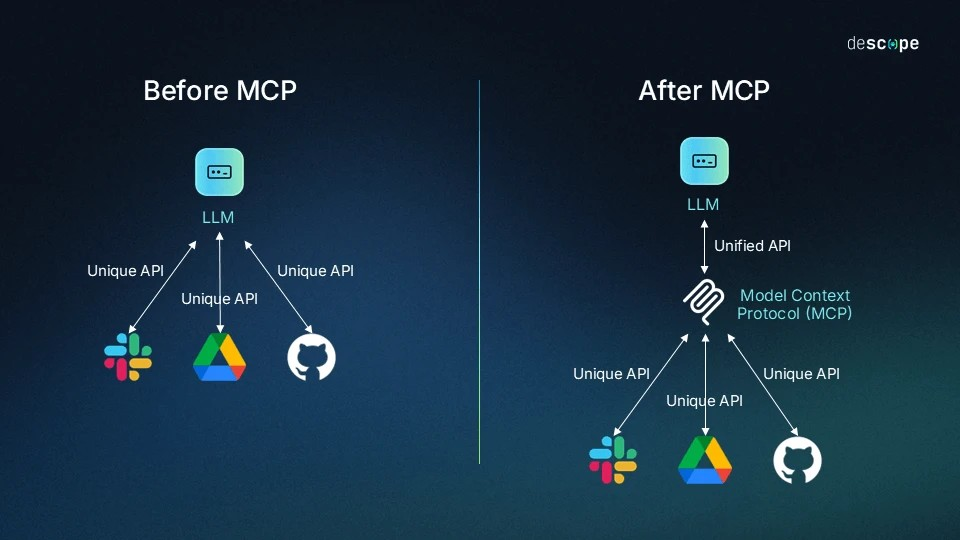

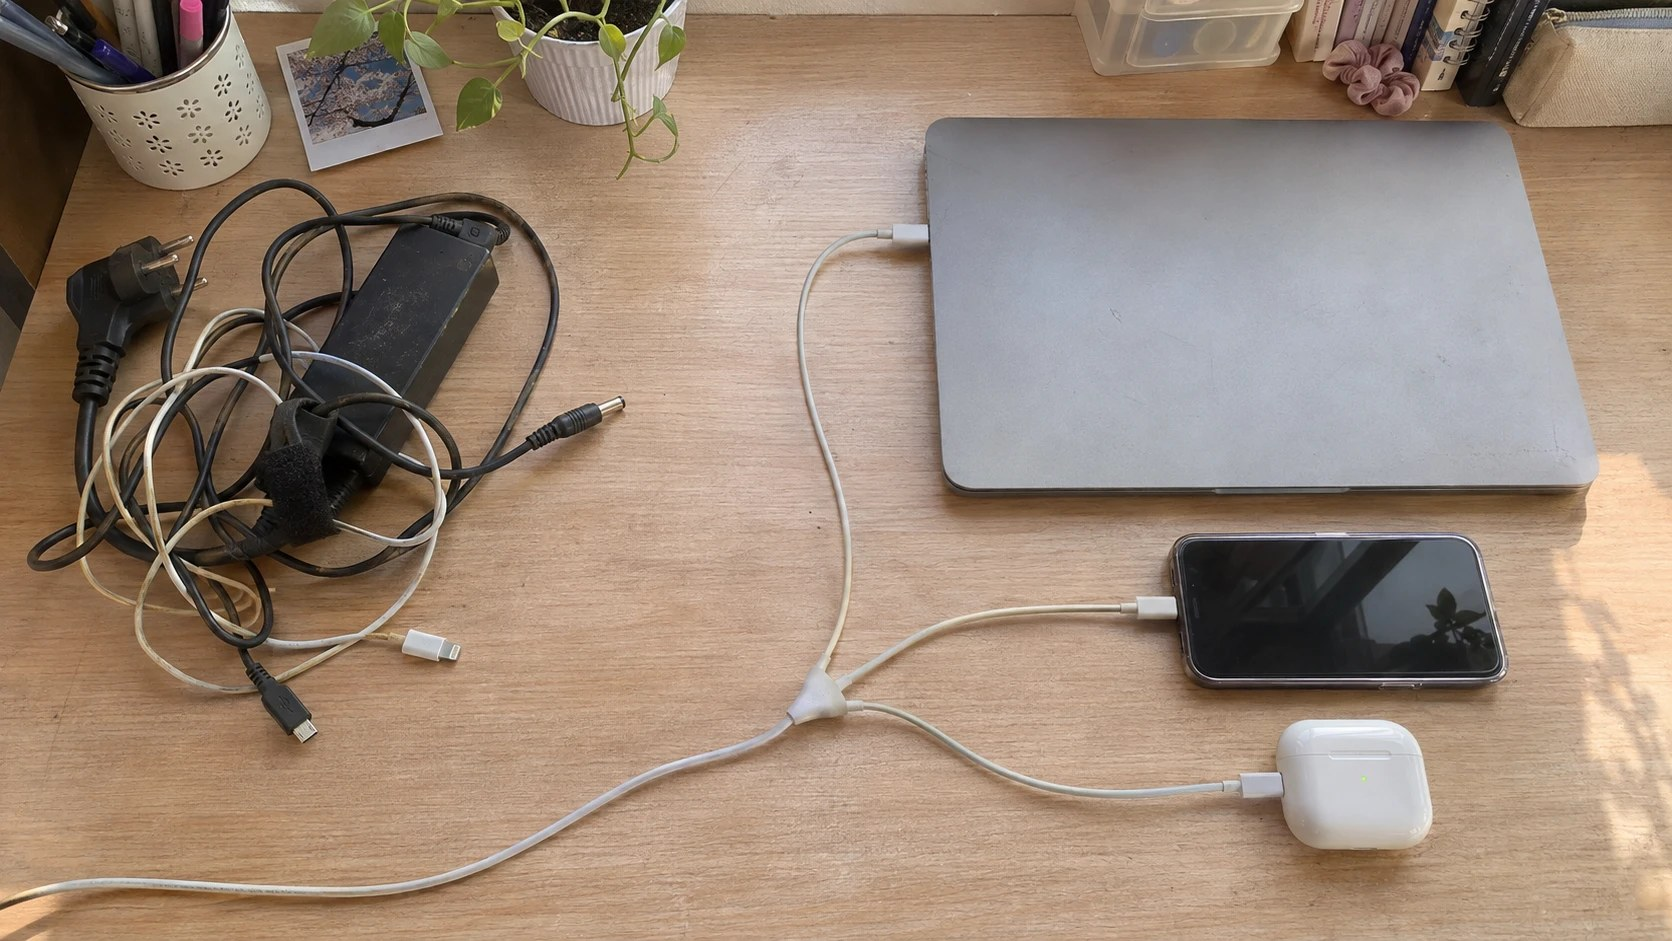

예전에는 핸드폰마다 충전기가 달랐는데 지금은 C타입 하나로 다 충전하는 것과 비슷합니다. Claude에서 노션이나 구글 드라이브 연결 버튼을 누르면 그 밑에서 MCP가 작동합니다.

Function Calling이랑 MCP는 경쟁하는게 아니라 같이 씁니다. MCP로 툴 목록을 가져오면 모델이 Function Calling으로 하나를 고르고, 앱이 다시 MCP로 실행합니다.

### MCP의 구조

- Host: 사용자가 쓰는 AI 앱입니다. 어떤 서버랑 툴을 허용할지 정합니다.
- Client: 호스트 안에서 서버랑 통신만 담당합니다. 서버 하나당 하나씩 있습니다.
- Server: 툴이나 데이터를 MCP 규격으로 내놓는 프로그램입니다.

### MCP 서버의 기본 요소

- Tools: 실행할 수 있는 행동
- Resources: 읽기만 하는 데이터
- Prompts: 다시 쓸 수 있는 템플릿

실제로 노션 MCP가 연결된 상태에서 "이번 주 회의록 요약해줘"라고 하면, 앱이 노션 서버에서 툴 목록을 받아 모델한테 주고, 모델이 검색 툴을 고르면 앱이 서버에 실행을 요청해서 찾아온 결과를 모델이 읽고 요약합니다.

## MCP의 한계

### 보안 문제

MCP는 보안은 정해지지 않아서 MCP를 썼을때 보안이 안전하다고 보장은 못합니다. 그래서 사용자 동의를 받고, 서버에 권한을 얼마나 줄지 호스트가 정합니다.

### 툴 문제

MCP 서버는 누구나 만들 수 있어서 출처를 모르는 서버를 연결하면 위험할 수 있습니다. 툴 설명은 사용자가 잘 안 봐서 누가 설명 안에 이상한 지시를 몰래 넣어도 모르고 넘어가 문제가 생길 수 있습니다.

### 프롬프트 주입

툴이 가져온 내용 안에 지시가 섞여 들어오는 것인데, 권한을 다 열어 두면 모델이 그 지시대로 마음대로 할 수 있어서 위험합니다. 그래서 필요한 권한만 주고, 되돌리기 어려운건 사람이 승인하는게 좋습니다.

## 데이터 구조화

### 필요한 이유

사내 AI를 만들때 가장 흔한 방법이 RAG인데, 문서를 여러 부분으로 나눠서 질문이랑 비슷한 데이터의 일부분만 가져오는 방식이라, 그 부분들이 서로 어떻게 연결되는지는 모릅니다.

예를 들어 "교육팀원이 어렵다고 한 세션은 누가 맡았어?"라고 물었을때 필요한 데이터의 일부분이 이렇게 흩어져 있다고 하면

1. 대흠이는 교육팀이다
2. 록희가 시계열 세션을 맡았다
3. 대흠이가 시계열 과제가 너무 어렵다고 했다

답은 2번에 있는데 질문에 나온 "교육팀"이 없어서 잘 안 뽑힙니다. 그렇다고 가져오는 양을 늘리면 상관없는 내용까지 같이 들어옵니다. 결국 데이터의 일부분끼리 어떻게 연결되는지 모르는게 문제라서 데이터를 구조화해야 합니다.

### 그래프 구조

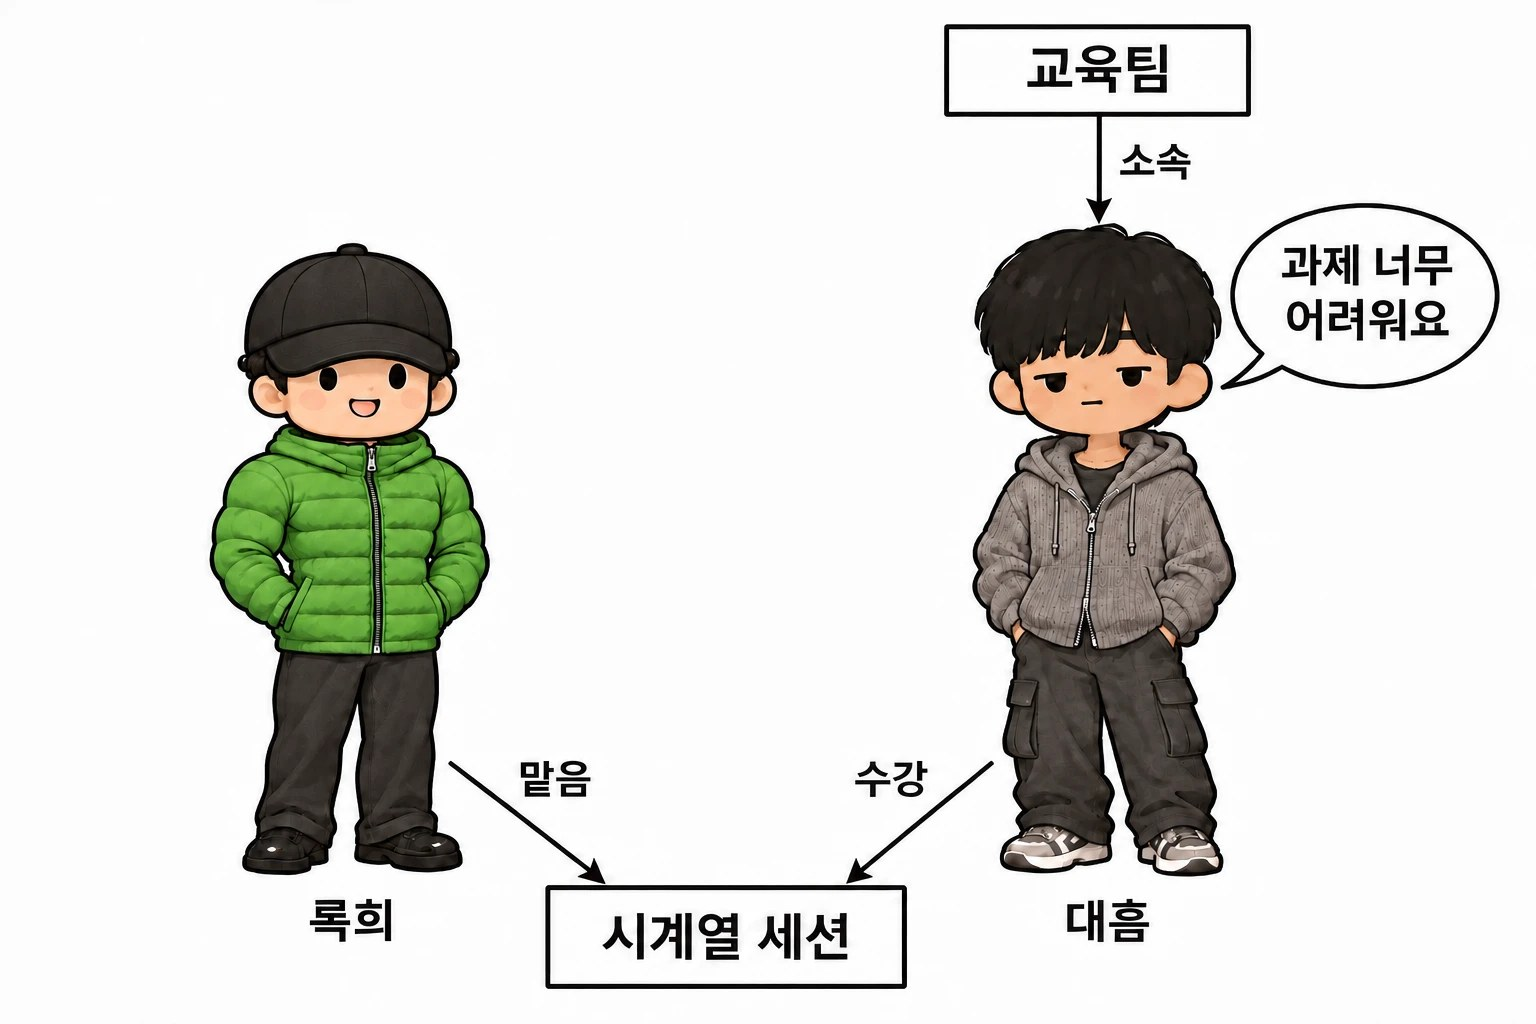

그래프는 노드와 엣지로 데이터를 표현합니다. 노드는 록희, 대흠이, 시계열 세션, 교육팀 같은 대상이고, 엣지는 "소속이다", "맡았다" 같은 관계입니다. 테이블은 무엇이 있는지를 저장한다면 그래프는 서로 어떻게 연결되어 있는지를 저장합니다.

### 팔란티어 온톨로지

팔란티어는 이 그래프 구조를 회사 전체에 적용해서 여기저기 흩어진 사내 데이터를 하나의 관계망으로 묶었습니다.

- 객체 타입: 테이블의 틀
- 객체: 테이블의 한 행
- 속성: 테이블의 열
- 링크 타입: 객체 사이의 관계
- 액션 타입: 데이터를 읽는 것뿐 아니라 알림 보내기 같은 행동까지 정의합니다. 일반 DB랑 가장 다른 점입니다.
- 역할: 직급이나 부서에 따라 볼 수 있는 범위를 정하고, AI 에이전트도 사람처럼 권한을 받아서 그 안에서만 움직입니다.

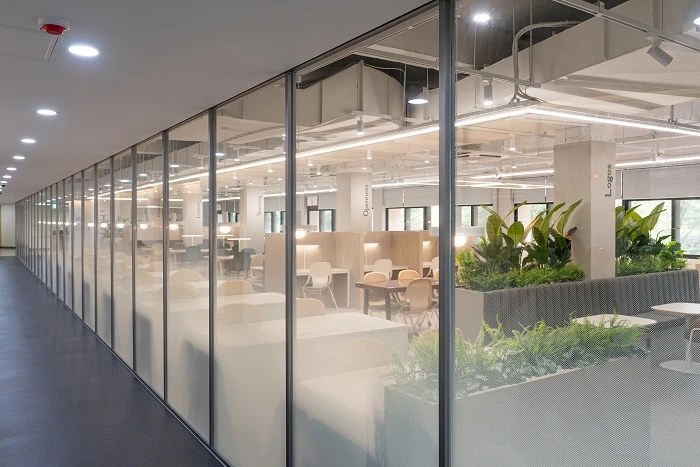

학교 도서관으로 치면 책 정보의 틀이 객체 타입, 책 한 권 한 권이 객체, 제목이나 청구기호가 속성, 학생이랑 빌린 책을 잇는게 링크입니다. 반납 기한이 지나면 연체 알림을 보내는게 액션 타입이고, 대출 기록은 도서관 직원만 볼 수 있게 하는게 역할입니다.

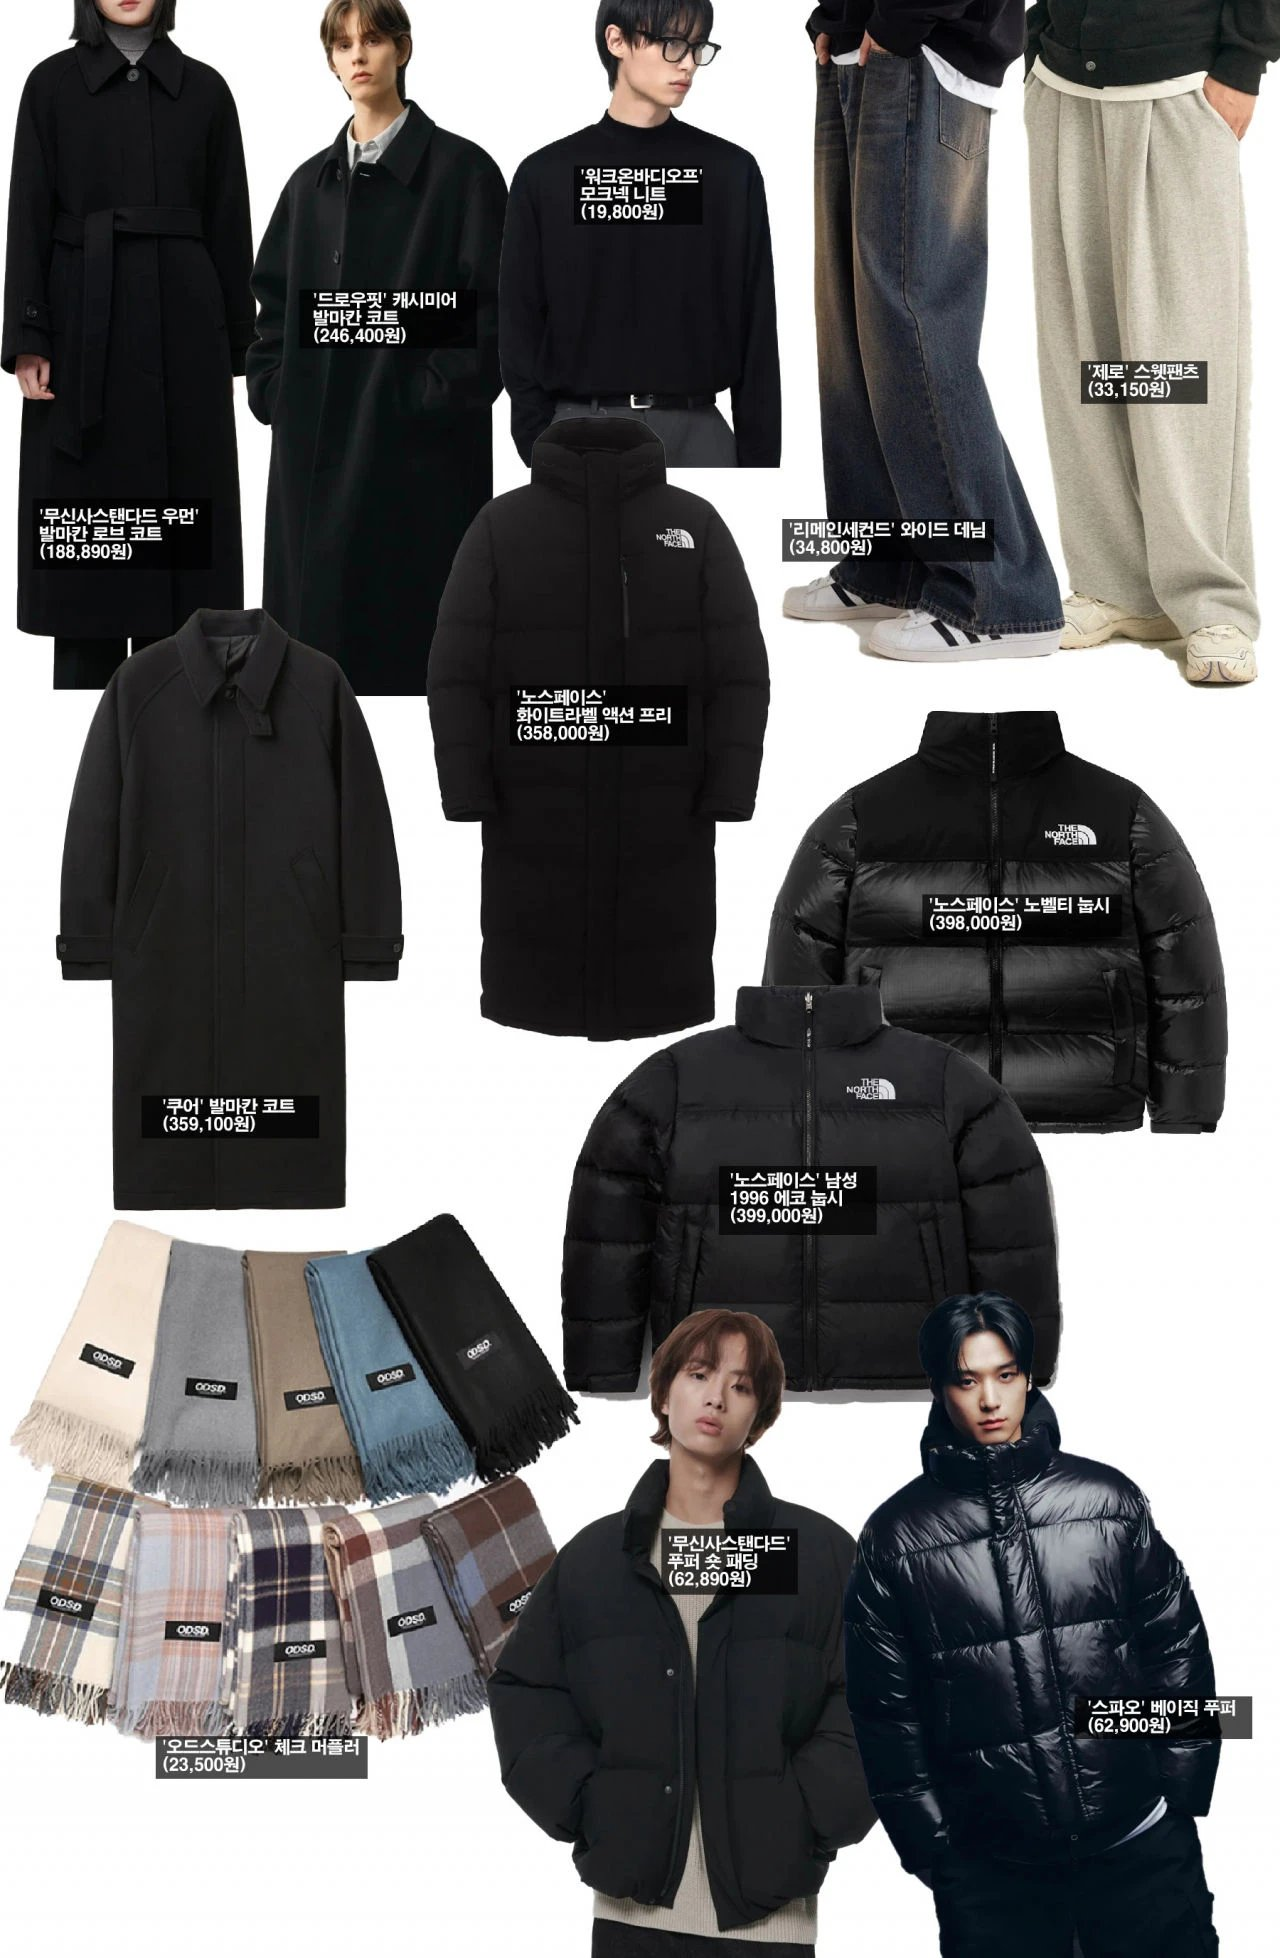

무신사로 치면 상품 정보의 틀이 객체 타입, 코트나 패딩 같은 상품 하나하나가 객체, 브랜드나 가격이 속성, 고객이랑 산 상품을 잇는게 링크입니다. 재고가 떨어지면 입고 알림을 보내는게 액션 타입이고, 판매자는 자기 상품 매출만 볼 수 있게 하는게 역할입니다.

테이블의 행이 그래프에서는 노드, 온톨로지에서는 객체가 되고, 테이블끼리 조인하던게 그래프에서는 엣지, 온톨로지에서는 링크가 됩니다.

## XAI

### 블랙박스가 왜 문제인가

딥러닝 모델은 파라미터가 너무 많고 복잡하게 얽혀 있어서 사람이 안을 읽을 수 없습니다. 입력을 넣으면 답은 나오는데 왜 그렇게 판단했는지는 모르는 블랙박스입니다. 그래서 모델이 잘못 학습했을때 어디가 문제인지 찾기 어렵습니다. 예를 들어 AI로 학회 지원서를 심사했는데 혜원이가 떨어졌다면, 왜 떨어졌는지 물어봐도 AI는 이유를 말해 주지 못합니다.

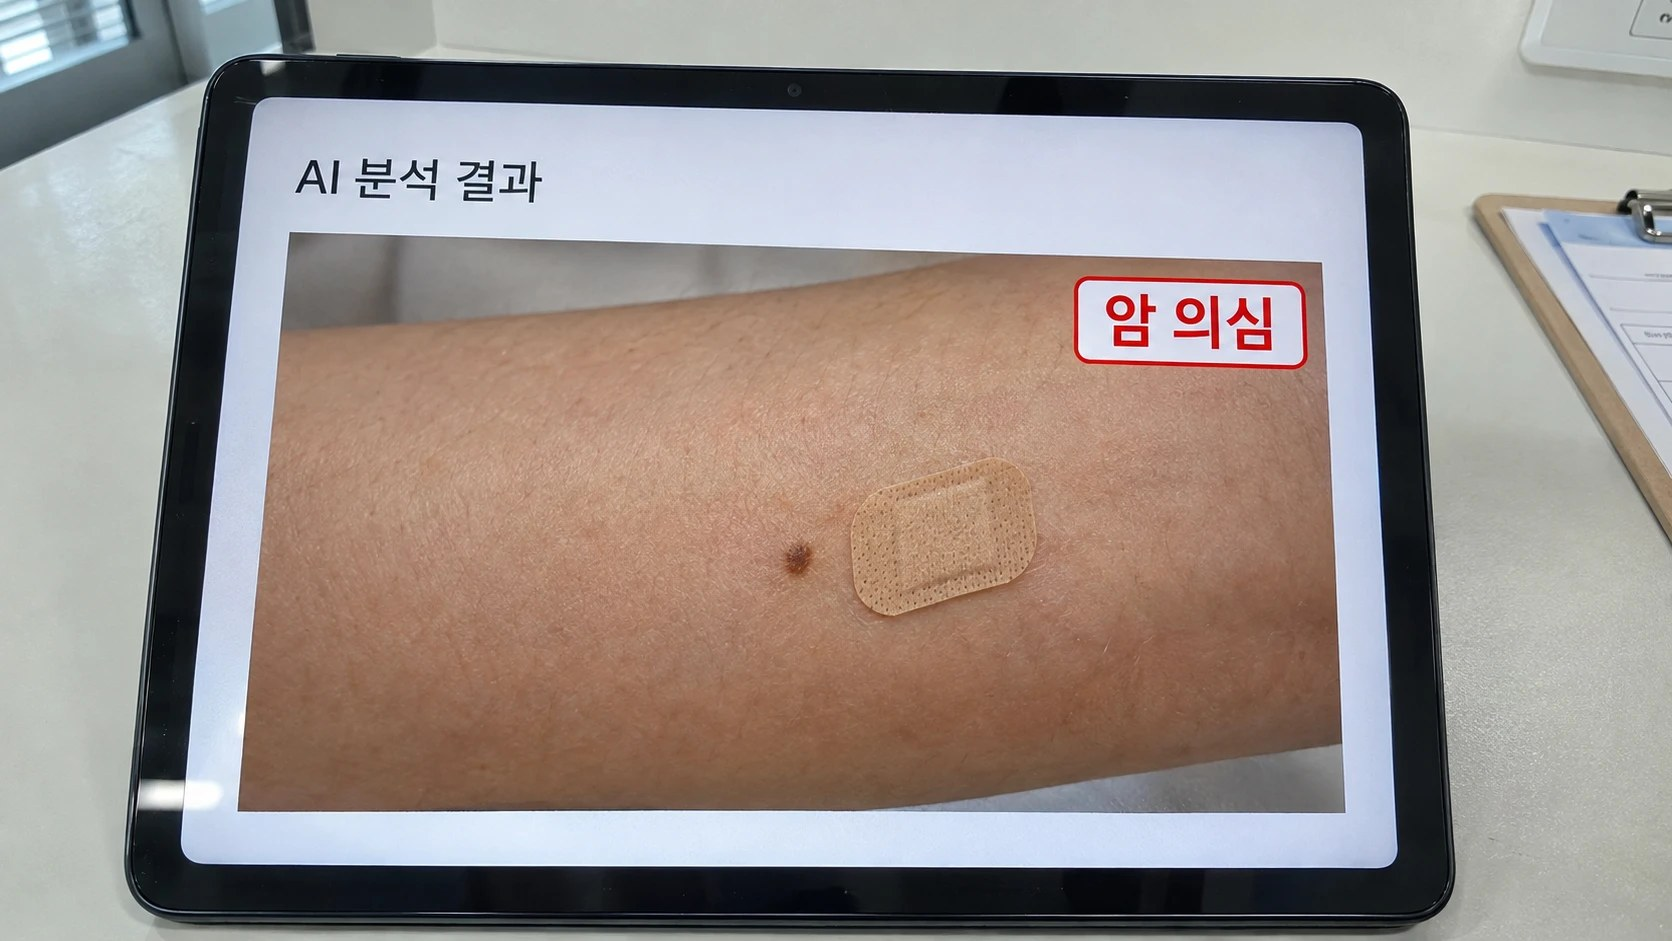

실제로 피부암 진단 AI가 반창고 붙은 사진을 암으로 판정하는 경우가 있었는데, 의사가 이미 본 병변 사진에 반창고가 많이 붙어 있어서 AI가 반창고를 암의 신호로 배운거였습니다. 입력이랑 결과만 봐서는 이런 문제를 찾을 수 없습니다.

### 기존 해결 시도들

- 회귀 분석: 계수를 직접 읽을 수 있어서 설명은 완벽하지만 복잡한 데이터에서는 성능이 낮습니다.
- SHAP, LIME: 모델은 그대로 두고 밖에서 입력을 조금씩 바꿔보며 어떤 특성이 결과에 얼마나 영향을 줬는지 추정합니다. 추정이라 진짜 이유가 아니라 그렇게 보이는 것일 수 있습니다.
- LLM에게 물어보기: 결과를 LLM에게 주고 이유를 물어보는 방법인데 LLM도 블랙박스라 그 설명이 맞는지 보장이 없습니다.

### Mechanistic Interpretability

밖에서 추정하는게 아니라 블랙박스를 직접 열어서 모델 안의 뉴런이나 어텐션 헤드가 어떤 일을 하는지 회로 수준까지 뜯어보는 연구입니다. 모델이 무엇을 답했는지가 아니라 어떻게 그 답에 도달했는지를 이해하려는 것입니다.

### 핵심 개념 3가지

- Feature: 모델이 입력에서 알아챈 개념입니다. 입력에 그 개념이 나오면 관련된 뉴런이 켜집니다.
- Circuit: 여러 뉴런과 어텐션 헤드가 연결되어 특정 기능을 하는 묶음입니다.
- Superposition: 표현해야 할 개념은 많은데 뉴런 수는 적어서 뉴런 하나에 여러 개념이 겹쳐 저장되는 것입니다. 그래서 뉴런 하나만 봐서는 무슨 개념인지 알기 어렵습니다. 이걸 풀려고 겹친 개념들을 하나씩 분리해서 꺼내는 Sparse Autoencoder를 씁니다.